# Tiny CDSE test: scientific validity

`validate_cdse_tiny.ipynb` checks units and whether the UDFs run. This notebook checks whether the **results make physical sense**, for the same AOI (1.5 x 1.5 km in the Senales valley, 1950-2750 m) and period (Oct 2022 - Aug 2023).

There is no in-situ snow data for this AOI, so each check is one of three kinds:

| Kind | Question | Example |
|---|---|---|
| **Independent sensor** | Does another sensor see the same snow? | Sentinel-2 snow map vs MODIS on the same day (Terra ~10:30, S2 ~10:20). |
| **Physical pattern** | Does snow behave as snow should in mountains? | More snow higher up; north faces keep snow longer; later melt-out higher up. |
| **Conservation** | Do the numbers add up? | Peak SWE cannot exceed the snowfall before it. |

Each check adds a row to the scorecard at the end: **PASS**, **FAIL**, or **CHECK** (rough literature range, not a hard limit). Every figure is followed by an *Interpretation* cell written from the results of the run on 2026-11-18; if the data change, reread the printed numbers.

In [1]:
# Setup: run sections 1-3 of validate_cdse_tiny.ipynb silently (loads the cubes, rebuilds swe_meteo,
# runs the SCA and SWE UDFs locally). Job submission/download cells are skipped.
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.utils.capture import capture_output

_nb = json.loads(Path('validate_cdse_tiny.ipynb').read_text(encoding='utf-8'))
with capture_output():
    for _cell in _nb['cells']:
        _src = ''.join(_cell['source'])
        if _cell['cell_type'] == 'markdown' and _src.startswith('## 4'):
            break
        if _cell['cell_type'] == 'code' and 'tiny.' not in _src:
            exec(_src, globals())
            plt.close('all')
print('loaded:', [n for n, d in ds.items() if d is not None], '| local SCA:', sca_local is not None, '| local SWE:', swe_local is not None)

loaded: ['raw_agera5', 'geopotential', 'raw_dem', 'raw_slope_aspect_vito', 'raw_modis', 'modis_scf', 'swe_meteo', 'snow', 'cp_occ'] | local SCA: True | local SWE: True


## 1. Terrain of the AOI

All checks below compare snow with elevation and aspect, on the 20 m Sentinel-2 snow grid. Aspect is grouped into north (315-45°), south (135-225°) and east/west.

snow grid {'t': 131, 'y': 79, 'x': 79} | elevation 1954..2756 m | facing: {'east/west': 2895, 'south': 2234, 'north': 1112}


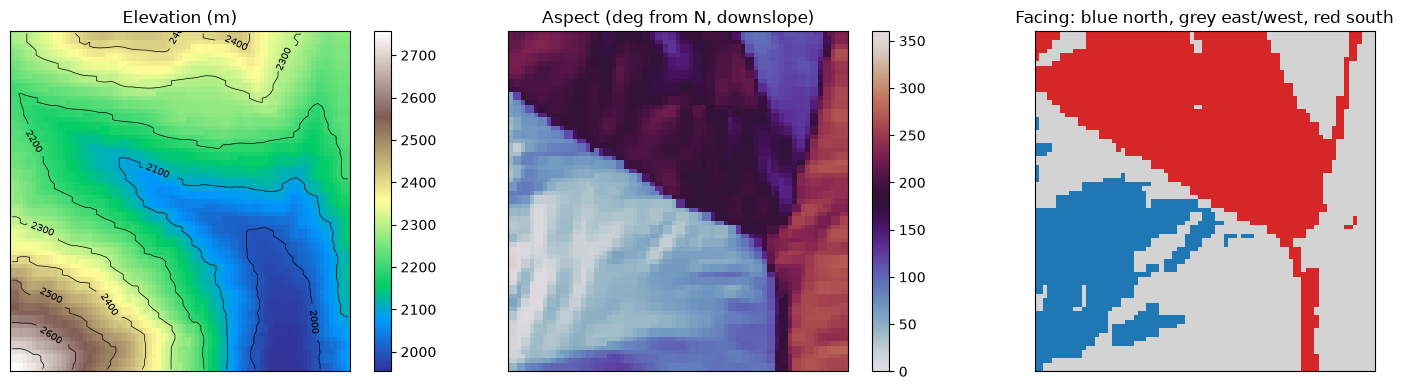

In [2]:
MONTHS = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]  # hydrological year order
MONTH_NAMES = dict(zip(MONTHS, ['Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug']))
checks = {}  # (area, check) -> row; rerunning a cell overwrites its rows


def check(area, name, value, expected, ok):
    """ok: True/False, or None for a soft literature range (CHECK)."""
    checks[area, name] = {'area': area, 'check': name, 'value': value, 'expected': expected,
                          'result': 'CHECK' if ok is None else ('PASS' if ok else 'FAIL')}


def spearman(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return pd.Series(a[m]).rank().corr(pd.Series(b[m]).rank())


def on_grid_of(a, src_crs, grid):
    """Nearest pixel of `a` (in src_crs) for each pixel of the UTM 32N snow grid."""
    gx, gy = np.meshgrid(grid.x.values, grid.y.values)
    px, py = Transformer.from_crs('EPSG:32632', src_crs, always_xy=True).transform(gx, gy)
    pts = dict(x=xr.DataArray(px, dims=('y', 'x')), y=xr.DataArray(py, dims=('y', 'x')))
    return a.sel(**pts, method='nearest').assign_coords(x=grid.x.values, y=grid.y.values).astype(float)


def ffill_t(a):
    """Forward-fill NaN along axis 0 (time); leading NaN stay NaN."""
    idx = np.where(~np.isnan(a), np.arange(a.shape[0])[:, None, None], 0)
    np.maximum.accumulate(idx, axis=0, out=idx)
    return np.take_along_axis(a, idx, axis=0)


grid = ds['snow']
elev = on_grid_of(dem['DEM'].squeeze('t', drop=True), 'EPSG:4326', grid)
aspect = on_grid_of(sa['ASP30'].squeeze('t', drop=True), 'EPSG:3035', grid)
facing = xr.where((aspect >= 315) | (aspect < 45), 'north', xr.where((aspect >= 135) & (aspect < 225), 'south', 'east/west'))
print(f'snow grid {dict(grid.sizes)} | elevation {float(elev.min()):.0f}..{float(elev.max()):.0f} m | '
      f'facing: {pd.Series(facing.values.ravel()).value_counts().to_dict()}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im = axes[0].imshow(elev, cmap='terrain'); axes[0].set_title('Elevation (m)'); plt.colorbar(im, ax=axes[0])
cs = axes[0].contour(elev, levels=range(2000, 2800, 100), colors='k', linewidths=0.5); axes[0].clabel(cs, fontsize=7)
im = axes[1].imshow(aspect, cmap='twilight', vmin=0, vmax=360); axes[1].set_title('Aspect (deg from N, downslope)'); plt.colorbar(im, ax=axes[1])
face_codes = {'north': 0, 'east/west': 1, 'south': 2}
im = axes[2].imshow(np.vectorize(face_codes.get)(facing.values), cmap=plt.matplotlib.colors.ListedColormap(['tab:blue', 'lightgrey', 'tab:red']))
axes[2].set_title('Facing: blue north, grey east/west, red south')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

**Interpretation:** the AOI is a cross-section of a valley. The floor (1950-2100 m) runs NW-SE through the centre and east. North of it is a **south-facing slope** (red, up to ~2450 m), and south-west of it a **north-facing slope** (blue) that rises to 2750 m in the SW corner. With 79 x 79 pixels of 20 m, 2234 south, 1112 north and 2895 east/west pixels, both slope types are well represented. This is a good AOI for testing aspect and elevation effects: physically, snow should leave the red slope first and stay longest in the high SW corner.

## 2. Sentinel-2 snow map vs MODIS (independent sensor)

On every date with both a Sentinel-2 snow map (`snow`: 0 free, 100 snow, 205 cloud) and a MODIS map (`modis_scf`: 0-100 % or 205), on the same 20 m grid:
- **Snow fraction:** S2 = snow pixels / clear pixels; MODIS = mean SCF over clear pixels. Compared on days where both are at least 50 % clear.
- **Pixel agreement:** S2 snow vs MODIS SCF >= 50 %, on pixels clear in both. The AOI is only 3 x 3 MODIS pixels, so expect mismatch at snow edges.
- **Clouds:** S2 and Terra pass within minutes. A day that MODIS sees as clear but S2 as fully cloudy points to a wrong S2 cloud mask.

**How to read:** top left, the dots of both sensors should overlap. Bottom left, both cloud-free shares should rise and fall together; red squares are suspicious S2 cloud days. Right, points should lie on the 1:1 line.

S2 dates: 131, MODIS dates: 99, common: 42, both >= 50 % clear: 6
snow fraction S2 - MODIS: bias -0.07, RMSE 0.11, r 0.95 | pixel agreement 0.71
MODIS clear but S2 fully cloudy: 11 of 17 days


,S2 clear share,MODIS clear share,S2 snow fraction,MODIS snow fraction
t,,,,
2022-11-17,0.99,0.82,0.20,0.09
2022-11-27,1.00,1.00,0.34,0.51
2023-01-06,1.00,1.00,0.68,0.75
2023-01-28,1.00,1.00,0.75,0.83
2023-01-31,1.00,1.00,0.67,0.77
2023-04-03,1.00,0.75,0.23,0.33


,S2 cloud (205) share,S2 no data (NaN) share,MODIS snow fraction
t,,,
2022-10-03,1.0,0.0,0.00
2022-11-02,1.0,0.0,0.00
2023-01-21,1.0,0.0,0.87
2023-03-27,1.0,0.0,0.64
2023-06-12,1.0,0.0,0.00
2023-07-02,1.0,0.0,0.00
2023-07-10,1.0,0.0,0.00
2023-07-12,1.0,0.0,0.00
2023-07-15,1.0,0.0,0.00


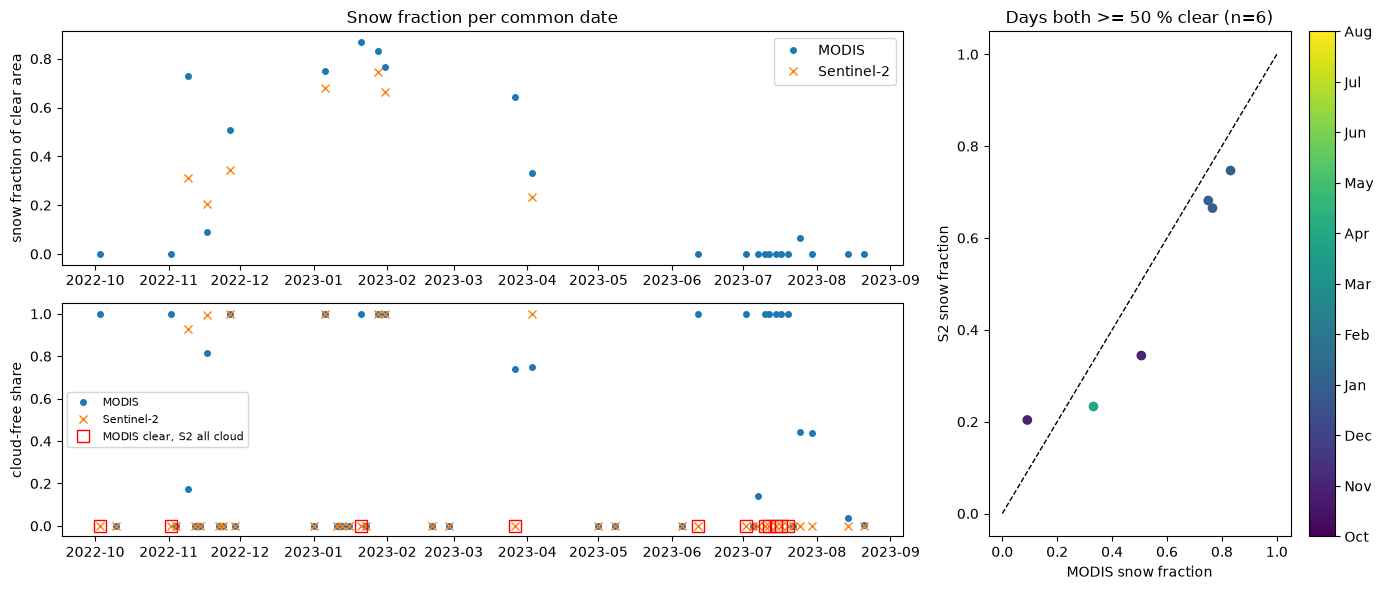

In [4]:
hr = ds['snow']['snow'].transpose('t', 'y', 'x')
hr_a, mo_a = xr.align(hr, ds['modis_scf']['scf'].transpose('t', 'y', 'x'), join='inner')  # common dates and pixels
hr_clear, mo_clear = hr_a.isin([0, 100]), mo_a <= 100
day = pd.DataFrame({
    'S2 clear share': hr_clear.mean(['x', 'y']).values,
    'MODIS clear share': mo_clear.mean(['x', 'y']).values,
    'S2 snow fraction': ((hr_a == 100).sum(['x', 'y']) / hr_clear.sum(['x', 'y'])).values,
    'MODIS snow fraction': (mo_a.where(mo_clear).mean(['x', 'y']) / 100).values,
}, index=hr_a.t.to_index())
both = day[(day['S2 clear share'] >= 0.5) & (day['MODIS clear share'] >= 0.5)]
diff = both['S2 snow fraction'] - both['MODIS snow fraction']
bias, rmse = diff.mean(), np.sqrt((diff ** 2).mean())
r = both['S2 snow fraction'].corr(both['MODIS snow fraction'])
pix = hr_clear & mo_clear & hr_a.t.isin(both.index.values)
pix_acc = float(((hr_a == 100) == (mo_a >= 50)).where(pix).mean())
mo_clear_days = day[day['MODIS clear share'] >= 0.5]
s2_lost = mo_clear_days[mo_clear_days['S2 clear share'] < 0.05]
s2_lost_kind = pd.DataFrame({'S2 cloud (205) share': (hr_a == 205).mean(['x', 'y']).to_pandas(),
                             'S2 no data (NaN) share': hr_a.isnull().mean(['x', 'y']).to_pandas(),
                             'MODIS snow fraction': day['MODIS snow fraction']}).loc[s2_lost.index]

print(f'S2 dates: {hr.sizes["t"]}, MODIS dates: {ds["modis_scf"].sizes["t"]}, common: {len(day)}, both >= 50 % clear: {len(both)}')
print(f'snow fraction S2 - MODIS: bias {bias:+.2f}, RMSE {rmse:.2f}, r {r:.2f} | pixel agreement {pix_acc:.2f}')
print(f'MODIS clear but S2 fully cloudy: {len(s2_lost)} of {len(mo_clear_days)} days')
display(both.round(2))
display(s2_lost_kind.round(2))

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(2, 3, (1, 2)); ax2 = fig.add_subplot(2, 3, (4, 5), sharex=ax1); ax3 = fig.add_subplot(2, 3, (3, 6))
ax1.plot(day.index, day['MODIS snow fraction'], 'o', ms=4, label='MODIS'); ax1.plot(day.index, day['S2 snow fraction'], 'x', label='Sentinel-2')
ax1.set_ylabel('snow fraction of clear area'); ax1.legend(); ax1.set_title('Snow fraction per common date')
ax2.plot(day.index, day['MODIS clear share'], 'o', ms=4, label='MODIS'); ax2.plot(day.index, day['S2 clear share'], 'x', label='Sentinel-2')
ax2.plot(s2_lost.index, s2_lost['S2 clear share'], 'rs', mfc='none', ms=9, label='MODIS clear, S2 all cloud')
ax2.set_ylabel('cloud-free share'); ax2.legend(fontsize=8)
sc = ax3.scatter(both['MODIS snow fraction'], both['S2 snow fraction'], c=both.index.month.map(MONTHS.index), cmap='viridis', vmin=0, vmax=len(MONTHS) - 1)
ax3.plot([0, 1], [0, 1], 'k--', lw=1); ax3.set_xlabel('MODIS snow fraction'); ax3.set_ylabel('S2 snow fraction')
ax3.set_title(f'Days both >= 50 % clear (n={len(both)})'); cb = plt.colorbar(sc, ax=ax3, ticks=range(len(MONTHS)))
cb.ax.set_yticklabels([MONTH_NAMES[m] for m in MONTHS])
plt.tight_layout()

check('S2 snow map', 'snow fraction bias vs MODIS', f'{bias:+.2f} (n={len(both)})', '|bias| < 0.15', abs(bias) < 0.15)
check('S2 snow map', 'snow fraction correlation vs MODIS', f'r = {r:.2f}', 'r > 0.7', r > 0.7)
check('S2 snow map', 'pixel agreement vs MODIS SCF >= 50 %', f'{pix_acc:.2f}', '> 0.8', pix_acc > 0.8)
check('S2 snow map', 'S2 all cloud while MODIS clear', f'{len(s2_lost)} / {len(mo_clear_days)} days',
      '< 20 % of days', len(s2_lost) < 0.2 * len(mo_clear_days))

**Interpretation**

- **When S2 produces a map, it is right.** On the 6 days where both sensors are mostly clear, the S2 snow fraction follows MODIS closely: r = 0.95, bias −0.07, RMSE 0.11. The slight underestimate is expected, because MODIS SCF ≥ 50 % at 500 m smooths patchy snow into "snow". Pixel agreement (0.71) is below the 0.8 target, but with 3 x 3 MODIS pixels in a valley with sharp snow lines, part of this is a footprint effect, not an S2 error.
- **S2 often produces no map at all, and that is wrong.** On 11 of the 17 days when MODIS sees the AOI as clear, every S2 pixel is 205 ("cloud"), not NaN. Six of those days are in a row in July, with MODIS clear and 0 % snow. Seven consecutive clear summer days cannot all be fully cloudy for S2 while clear for Terra 10 minutes later.
- **Cause (from the code):** `representative_pixels.py` trains an SVM on snow *and* snow-free training pixels. If one class is missing, it writes 255 for the whole chunk, and `snow_map_from_snow_cover_fraction` turns 255 into 205. In 9 of the 11 lost days MODIS shows 0 % snow, so there is no snow class. A snow-free (or fully snow-covered) clear scene is therefore labelled as cloud. The 1.5 km AOI makes this extreme, but it also happens in production for any snow-free neighbourhood chunk (summer, low elevations).

## 3. Sentinel-2 snow map: elevation and aspect patterns

Only clear S2 observations (0 or 100). Snow frequency = share of clear observations that are snow, per 100 m elevation band and month.

Expected in an Alpine valley at 2000-2750 m:
- **Elevation:** each column gets bluer (more snow) towards the top, strongest in autumn and spring when the snow line is inside the AOI.
- **Season:** snow from about November to April/May, none in summer.
- **Aspect:** in spring, north faces keep snow longer than south faces.

Grey cells have fewer than 200 clear pixel observations.

clear S2 dates per month: {'Oct': 0, 'Nov': 4, 'Dec': 4, 'Jan': 4, 'Feb': 5, 'Mar': 4, 'Apr': 5, 'May': 1, 'Jun': 0, 'Jul': 0, 'Aug': 0}
clear pixel obs per month: {'Oct': 0, 'Nov': 24360, 'Dec': 23573, 'Jan': 24964, 'Feb': 31203, 'Mar': 17873, 'Apr': 23834, 'May': 6235, 'Jun': 0, 'Jul': 0, 'Aug': 0}
spring (Mar-May) snow frequency by band: {1900: 0.13, 2000: 0.11, 2100: 0.2, 2200: 0.29, 2300: 0.25, 2400: 0.36, 2500: 0.47, 2600: 0.42, 2700: 0.52} -> rank corr with elevation 0.95
spring snow frequency by facing: {'east/west': 0.26, 'north': 0.56, 'south': 0.04} (pixel obs: {'east/west': 22172, 'south': 17062, 'north': 8708})


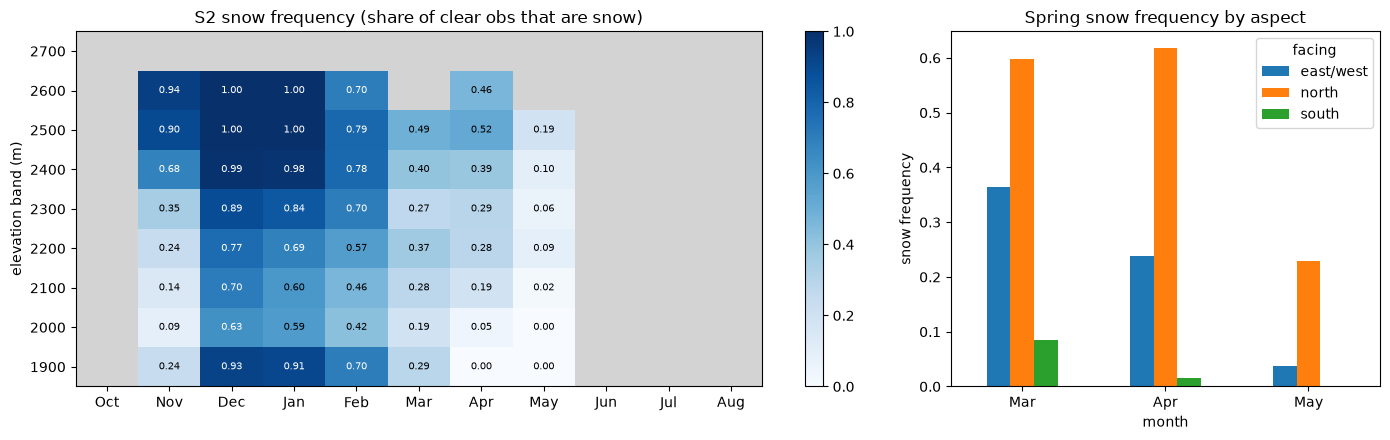

In [5]:
def obs_table(a):
    """Clear pixel observations (0/100) of a (t, y, x) DataArray -> DataFrame with terrain and month."""
    v = a.transpose('t', 'y', 'x').values
    valid = np.isin(v, (0, 100))
    b = lambda x: np.broadcast_to(x, v.shape)[valid]
    return pd.DataFrame({'snow': v[valid] == 100, 'elev_band': b((elev.values // 100) * 100).astype(int),
                         'facing': b(facing.values), 'month': b(a.t.dt.month.values[:, None, None])})


obs = obs_table(hr)
freq = obs.pivot_table(index='elev_band', columns='month', values='snow', aggfunc='mean').reindex(columns=MONTHS)
count = obs.pivot_table(index='elev_band', columns='month', values='snow', aggfunc='size').reindex(columns=MONTHS)
freq = freq.where(count >= 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})
cmap = plt.get_cmap('Blues').copy(); cmap.set_bad('lightgrey')
im = axes[0].imshow(freq.values, origin='lower', aspect='auto', cmap=cmap, vmin=0, vmax=1)
axes[0].set_xticks(range(len(MONTHS)), [MONTH_NAMES[m] for m in MONTHS]); axes[0].set_yticks(range(len(freq)), freq.index)
axes[0].set_ylabel('elevation band (m)'); axes[0].set_title('S2 snow frequency (share of clear obs that are snow)')
for (i, j), v in np.ndenumerate(freq.values):
    if np.isfinite(v):
        axes[0].text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > 0.6 else 'black')
plt.colorbar(im, ax=axes[0])

spring = obs[obs.month.isin([3, 4, 5])]
by_facing = spring.pivot_table(index='month', columns='facing', values='snow', aggfunc='mean').rename(index=MONTH_NAMES)
by_facing.plot.bar(ax=axes[1], rot=0, title='Spring snow frequency by aspect'); axes[1].set_ylabel('snow frequency')
plt.tight_layout()

band_frac = spring.groupby('elev_band')['snow'].mean()
rho_elev = spearman(band_frac.index.values.astype(float), band_frac.values)
facing_frac = spring.groupby('facing')['snow'].mean()
summer_snow = obs[obs.month.isin([7, 8])]['snow'].mean()
print('clear S2 dates per month:', {MONTH_NAMES[m]: int(c) for m, c in
                                    pd.Series(hr.t.dt.month.values[np.isin(hr.values, (0, 100)).any((1, 2))]).value_counts().reindex(MONTHS).fillna(0).items()})
print('clear pixel obs per month:', {MONTH_NAMES[m]: int(c) for m, c in count.sum().items()})
print(f'spring (Mar-May) snow frequency by band: {band_frac.round(2).to_dict()} -> rank corr with elevation {rho_elev:.2f}')
print(f'spring snow frequency by facing: {facing_frac.round(2).to_dict()} (pixel obs: {spring.facing.value_counts().to_dict()})')

check('S2 snow map', 'spring snow increases with elevation', f'rank corr {rho_elev:.2f}', '> 0', rho_elev > 0)
check('S2 snow map', 'spring snow north > south', f'N {facing_frac.get("north", np.nan):.2f} / S {facing_frac.get("south", np.nan):.2f}',
      'N > S', facing_frac.get('north', 0) > facing_frac.get('south', 0))
check('S2 snow map', 'Jul-Aug clear obs available', f'{int((obs.month.isin([7, 8])).sum())} pixel obs, snow {summer_snow:.2f}',
      'many obs, snow ~0', (obs.month.isin([7, 8])).sum() > 1000 and summer_snow < 0.05)

**Interpretation**

- **Elevation: physically right.** In spring the snow frequency rises almost monotonically from 0.11-0.13 at 1900-2000 m to ~0.5 at 2500-2700 m (rank correlation 0.95). In Nov, Mar and Apr the snow line is visibly inside the AOI. In Dec-Jan almost everything above 2300 m is snow.
- **Aspect: physically right and strong.** In spring the north faces are snow-covered in 56 % of clear observations, east/west in 26 %, and south faces in only 4 %. The south-facing slope loses its snow by March, which is what you expect in a dry winter with strong March sun.
- **One local oddity:** the lowest band (1900 m, valley floor) is snowier in Dec-Feb (0.91-0.93) than 2000-2200 m. This is plausible (a flat, shaded valley bottom with cold-air pooling keeps snow), not a sign of an error.
- **No clear S2 observations from June to October** (0 clear dates, "Jul-Aug obs" FAIL). This is the missing-class problem from section 2, not real weather. As a result, the summer "no snow" state and the autumn onset are never observed by S2.

## 4. Reconstructed SCA (local SCA UDF)

The reconstruction fills cloudy pixels of the S2 snow map using MODIS and each pixel's snow history (cp/occ). Checks:
- **Fidelity:** where S2 saw the ground (0/100), the output must keep that value; the reconstruction may only fill gaps.
- **Gap filling:** share of 205 (unknown) left per month. Days without an S2 image count as unknown in the input.
- **Temporal consistency:** snow/no-snow flips per pixel over the season, unknown days skipped. A real season has a few (onset, melt-out, some early snowfalls that melt). Dozens mean noise.
- **Melt-out:** last snow date per pixel after 1 Feb; should be later higher up and on north faces.

**How to read:** (1) orange bars should be far below blue bars; (2) flip map should be mostly dark; (3) melt-out map should follow the terrain map of section 1; (4) points should rise to the right, blue (north) above red (south).

SCA dates: 188 (2022-10-03 .. 2023-08-31)
fidelity on clear S2 pixels: 1.0000
unknown share overall: input 0.87 -> reconstructed 0.62
snow/no-snow flips per pixel: median 6, p90 8, max 12
melt-out after 1 Feb found for 82% of pixels; gradient +4.4 days per 100 m
median melt-out by facing: {'east/west': '10 Apr', 'north': '26 Apr', 'south': '22 Mar'}
distinct melt-out dates: ['01 Apr', '03 Apr', '03 May', '05 Feb', '06 Apr', '07 Mar', '10 Apr', '10 Feb', '12 Feb', '15 Feb', '17 Apr', '18 Apr', '19 Mar', '22 Mar', '25 Feb', '26 Apr', '27 Mar']


month,Oct,Nov,Dec,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug
input (S2),1.00,0.82,0.73,0.85,0.62,0.80,0.75,0.94,1.00,1.00,1.00
reconstructed,0.74,0.52,0.63,0.65,0.56,0.71,0.65,0.81,0.77,0.14,0.92


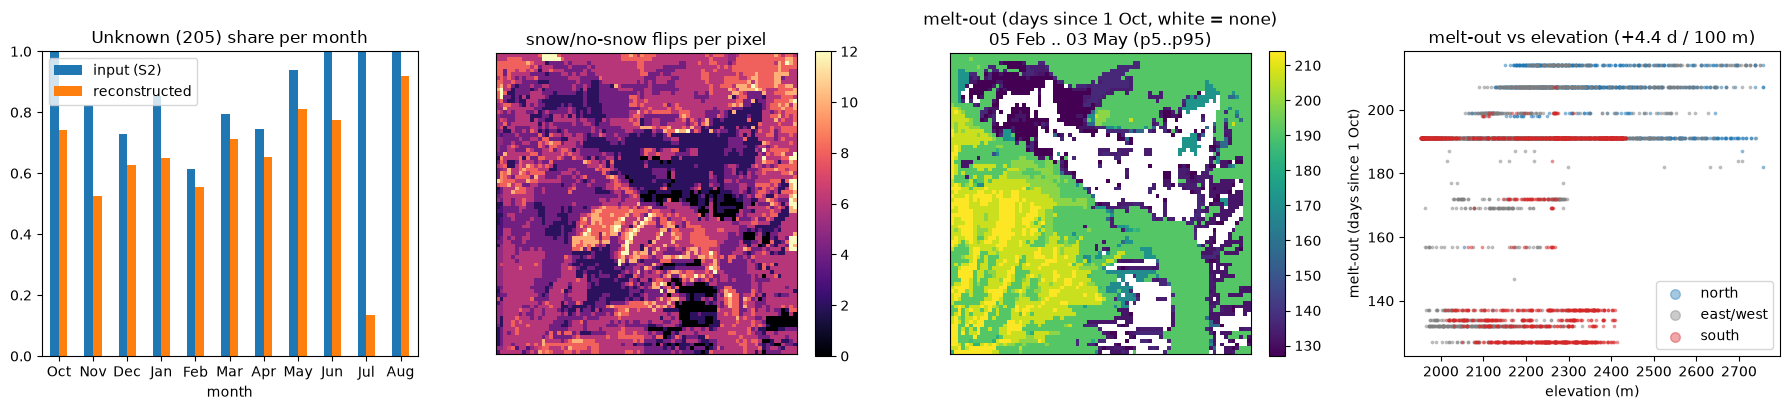

In [6]:
rec = sca_local.drop_vars('bands', errors='ignore').transpose('t', 'y', 'x')
inp = si['snow'].transpose('t', 'y', 'x').values
rec_v = rec.values.astype(float)
months = rec.t.dt.month.values

clear_in = np.isin(inp, (0, 100))
fidelity = (rec_v[clear_in] == inp[clear_in]).mean()
unknown = pd.DataFrame({'input (S2)': (~clear_in).mean((1, 2)), 'reconstructed': (rec_v == 205).mean((1, 2)), 'month': months})
unknown_m = unknown.groupby('month').mean().reindex(MONTHS).rename(index=MONTH_NAMES)

filled = ffill_t(np.where(rec_v == 205, np.nan, rec_v))
d = np.diff(filled, axis=0)
flips = ((d != 0) & ~np.isnan(d)).sum(0)

t_idx = np.arange(rec.sizes['t'])[:, None, None]
after_feb = (rec.t >= np.datetime64('2023-02-01')).values[:, None, None]
last = np.where((rec_v == 100) & after_feb, t_idx, -1).max(0)
melt_out = np.where(last >= 0, (rec.t.values[np.clip(last, 0, None)] - np.datetime64('2022-10-01')) / np.timedelta64(1, 'D'), np.nan)
m = np.isfinite(melt_out)
grad = np.polyfit(elev.values[m], melt_out[m], 1)[0] * 100 if m.sum() > 10 else np.nan
mo_by_face = pd.Series(melt_out.ravel()).groupby(facing.values.ravel()).median()

print(f'SCA dates: {rec.sizes["t"]} ({str(rec.t.values[0])[:10]} .. {str(rec.t.values[-1])[:10]})')
print(f'fidelity on clear S2 pixels: {fidelity:.4f}')
print(f'unknown share overall: input {(~clear_in).mean():.2f} -> reconstructed {(rec_v == 205).mean():.2f}')
print(f'snow/no-snow flips per pixel: median {np.median(flips):.0f}, p90 {np.percentile(flips, 90):.0f}, max {flips.max()}')
print(f'melt-out after 1 Feb found for {m.mean():.0%} of pixels; gradient {grad:+.1f} days per 100 m')
print('median melt-out by facing:', {k: f'{pd.Timestamp("2022-10-01") + pd.Timedelta(days=v):%d %b}' for k, v in mo_by_face.items()})
print('distinct melt-out dates:', sorted({f'{pd.Timestamp("2022-10-01") + pd.Timedelta(days=v):%d %b}' for v in np.unique(melt_out[m])}))
display(unknown_m.round(2).T)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
unknown_m[['input (S2)', 'reconstructed']].plot.bar(ax=axes[0], rot=0, title='Unknown (205) share per month'); axes[0].set_ylim(0, 1)
im = axes[1].imshow(flips, cmap='magma'); axes[1].set_title('snow/no-snow flips per pixel'); plt.colorbar(im, ax=axes[1])
mo_dates = pd.Timestamp('2022-10-01') + pd.to_timedelta(np.nanpercentile(melt_out, [5, 95]), 'D')
im = axes[2].imshow(melt_out, cmap='viridis'); axes[2].set_title(f'melt-out (days since 1 Oct, white = none)\n{mo_dates[0]:%d %b} .. {mo_dates[1]:%d %b} (p5..p95)')
plt.colorbar(im, ax=axes[2])
for face, c in [('north', 'tab:blue'), ('east/west', 'tab:grey'), ('south', 'tab:red')]:
    s = (facing.values == face) & m
    axes[3].scatter(elev.values[s], melt_out[s], s=3, c=c, alpha=0.4, label=face)
axes[3].set_xlabel('elevation (m)'); axes[3].set_ylabel('melt-out (days since 1 Oct)'); axes[3].legend(markerscale=4)
axes[3].set_title(f'melt-out vs elevation ({grad:+.1f} d / 100 m)')
for ax in axes[1:3]:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

check('SCA reconstruction', 'keeps clear S2 observations', f'{fidelity:.4f}', '1.0', fidelity > 0.999)
check('SCA reconstruction', 'unknown (205) left', f'{(rec_v == 205).mean():.2f} (input {(~clear_in).mean():.2f})', '< 0.10', (rec_v == 205).mean() < 0.10)
check('SCA reconstruction', 'snow/no-snow flips per pixel', f'median {np.median(flips):.0f}, p90 {np.percentile(flips, 90):.0f}',
      'median <= 6', np.median(flips) <= 6)
check('SCA reconstruction', 'melt-out later at higher elevation', f'{grad:+.1f} d / 100 m', '> 0', grad > 0)
check('SCA reconstruction', 'melt-out later on north faces', f'N {mo_by_face.get("north", np.nan):.0f} / S {mo_by_face.get("south", np.nan):.0f} d',
      'N > S', mo_by_face.get('north', 0) > mo_by_face.get('south', 0))

**Interpretation**

- **Fidelity is perfect (1.0000).** The reconstruction never changes a clear S2 observation.
- **Gap filling is limited.** The unknown share drops from 0.87 to 0.62, which is still far above the 10 % target. Only July comes close (0.14), because MODIS is clear there. Two reasons:
  1. S2 scenes are lost to the missing-class problem (section 2).
  2. The CDSE MODIS collection is sparse: 99 of ~335 days, with almost nothing in August, hence 0.92 unknown.
- **Temporal noise is borderline.** The median is 6 snow/no-snow flips per pixel, at the limit (p90 8, max 12). The bright stripes on the north-facing slope in the flip map show that pixels alternate between snow and no snow. This is more than onset + melt-out + a few early snowfalls, and points to S2/MODIS disagreement at the snow edge.
- **Melt-out pattern: physically right.** The white area (no snow after 1 Feb) is exactly the south-facing slope of section 1. The latest melt-out (yellow, early May) is on the high north-facing SW corner. Median melt-out is 22 Mar on south faces, 10 Apr on east/west and 26 Apr on north faces, with +4.4 days per 100 m.
- **Melt-out is coarse in time.** Melt-out can only fall on the 17 dates with a clear observation, which gives the horizontal bands in the scatter plot. A melt-out "on 3 May" means "between the last clear snow day and the next clear day", which can be weeks.

## 5. Meteo forcing: how much snow can fall?

Upper bound for the SWE check. The offline `swe_meteo` is put on the snow grid and precipitation is split with the SWE UDF's own rules:
- **Snowfall (physical):** precipitation on days with T < 2 °C (`temperature_threshold`).
- **Snowfall counted by the UDF:** same, but only on days with P > 5 mm (`precipitation_threshold`). (The UDF also counts warm wet days when basin SCA rises > 10 points; not included here.)

**How to read:** left, the gap between the orange line (physical snowfall) and the green dashed line (counted by the UDF) is snowfall the UDF ignores as accumulation. Right, snowfall vs elevation via the temperature lapse rate; precipitation itself is uniform because the AOI is one AGERA5 pixel.

AOI-mean totals 1 Oct - 31 May (mm): {'precipitation': 623, 'snowfall (T < 2 °C)': 428, 'snowfall counted by UDF (also P > 5 mm)': 269}
cold-day precipitation on days <= 5 mm (ignored as accumulation by the UDF): 37%
AOI-mean temperature by month (°C): {'Oct': 5.0, 'Nov': -3.4, 'Dec': -7.5, 'Jan': -8.3, 'Feb': -5.8, 'Mar': -3.3, 'Apr': -1.9, 'May': 3.9, 'Jun': 8.9, 'Jul': 10.8, 'Aug': 10.5}


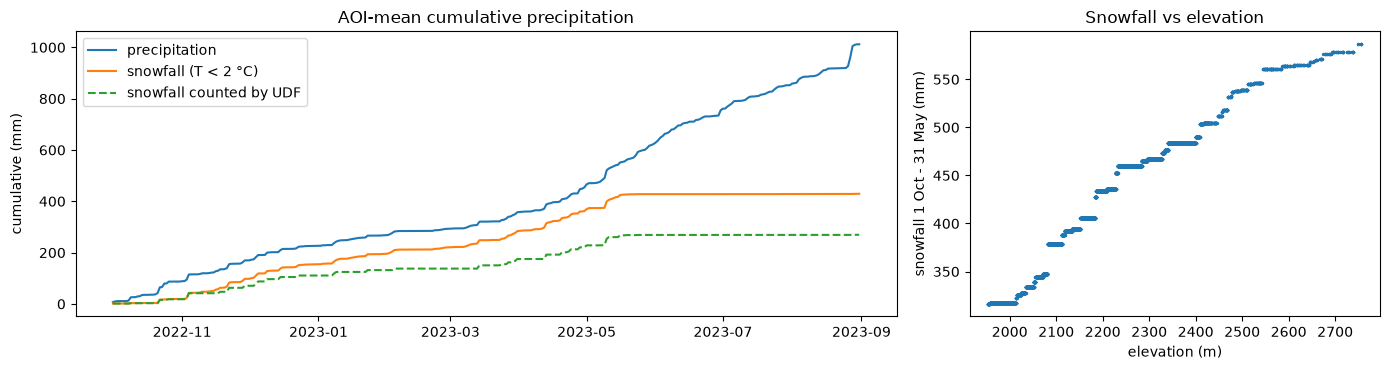

In [7]:
T_THR, P_THR = 2.0, 5.0  # SWE UDF DEFAULTS temperature_threshold / precipitation_threshold
met = ds['swe_meteo']
daily_grid = rec.reindex(t=met.t.values)  # daily time axis on the snow grid
ta_d, pr_d, sw_d = met_on(daily_grid, met)
cold = ta_d < T_THR
snowfall = pr_d.where(cold, 0)
snowfall_udf = pr_d.where(cold & (pr_d > P_THR), 0)
season = slice('2022-10-01', '2023-05-31')
tot = {k: float(v.sel(t=season).sum('t').mean()) for k, v in
       [('precipitation', pr_d), ('snowfall (T < 2 °C)', snowfall), ('snowfall counted by UDF (also P > 5 mm)', snowfall_udf)]}
lost = 1 - tot['snowfall counted by UDF (also P > 5 mm)'] / tot['snowfall (T < 2 °C)']
print('AOI-mean totals 1 Oct - 31 May (mm):', {k: round(v) for k, v in tot.items()})
print(f'cold-day precipitation on days <= {P_THR:.0f} mm (ignored as accumulation by the UDF): {lost:.0%}')
print(f'AOI-mean temperature by month (°C):', ta_d.mean(['x', 'y']).groupby('t.month').mean().round(1).to_pandas().reindex(MONTHS).rename(index=MONTH_NAMES).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [2, 1]})
for (k, v), ls in zip([('precipitation', pr_d), ('snowfall (T < 2 °C)', snowfall), ('snowfall counted by UDF', snowfall_udf)], ['-', '-', '--']):
    axes[0].plot(v.t, v.mean(['x', 'y']).cumsum('t'), ls, label=k)
axes[0].set_ylabel('cumulative (mm)'); axes[0].legend(); axes[0].set_title('AOI-mean cumulative precipitation')
sf_season = snowfall.sel(t=season).sum('t').values
axes[1].scatter(elev.values.ravel(), sf_season.ravel(), s=2)
axes[1].set_xlabel('elevation (m)'); axes[1].set_ylabel('snowfall 1 Oct - 31 May (mm)'); axes[1].set_title('Snowfall vs elevation')
plt.tight_layout()

check('Meteo', 'season snowfall (T < 2 °C), AOI mean', f'{tot["snowfall (T < 2 °C)"]:.0f} mm', 'order 200-800 mm (rough)', None)
check('Meteo', 'snowfall ignored by 5 mm/day threshold', f'{lost:.0%}', '< 30 %', lost < 0.3)

**Interpretation**

- **The forcing is plausible.** From 1 Oct to 31 May, 623 mm of precipitation falls, of which 428 mm as snow (T < 2 °C) on the AOI mean. Snowfall increases from ~320 mm at 1950 m to ~590 mm at 2750 m, only through temperature, because precipitation is a single AGERA5 pixel. Monthly mean temperature goes from −8.3 °C (Jan) to −1.9 °C (Apr) and +3.9 °C (May) at a mean height of ~2350 m. This is plausible for an inner-Alpine valley in a dry, cold-spring year.
- **The 5 mm/day threshold drops 37 % of the snowfall as accumulation** (FAIL, target < 30 %). The green dashed line ends at 269 mm instead of 428 mm. Totals are still conserved by the UDF (melt is redistributed), but accumulation is put on fewer, bigger days. In a dry inner-Alpine climate with many small snowfalls this threshold is too high.
- **Main point for section 6:** the snow that fell is ~430 mm on average. A peak SWE of a few hundred mm is therefore physically possible.

## 6. SWE: conservation and plausibility

The SWE UDF works backwards: it sums modelled melt (temperature + shortwave × (1 − albedo)) from each melt-out date back to the start of the snow period, then spreads that total over the accumulation days in proportion to their precipitation. It needs:
1. **A daily SCA without gaps:** a period only ends when a pixel goes 100 → 0 between two consecutive steps; a 205 step breaks it.
2. **Observed melt-out dates.**

The UDF is run twice:
- **as fed:** the reconstructed SCA on its own irregular dates, clouds still in it (current pipeline behaviour).
- **daily, gap-filled:** reconstructed SCA on a daily axis, each pixel's unknown days filled from its nearest clear day. A stand-in for a complete SCA, to test the SWE model separately from SCA gaps.

Checks on the daily run: SWE > 0 where SCA = snow and 0 where no snow; **mass:** peak SWE ≤ snowfall before the peak; peak SWE rises with elevation; melt rates ~5-30 mm/day (UDF cap 60); AOI-mean peak ~100-400 mm for the low-snow winter 2022/23 (rough).

**How to read:** top, the blue line (SWE) should rise during winter towards, but stay below, the dashed line (cumulative snowfall) and drop to 0 at melt-out. Bottom: peak SWE map, ratio map (blue < 1 fine, red > 1 = water from nothing), melt-out map, and peak SWE vs elevation (should rise to the right).

SCA time steps (days): {1: 80, 2: 70, 3: 36, 4: 1}
as fed:           AOI-mean peak 0 mm, NaN share 0.73
daily gap-filled: AOI-mean peak 8 mm on 2023-02-04, pixel peak p50 0 / p95 28 / max 125 mm
SWE > 0 where SCA = snow: 0.36 | SWE = 0 where SCA = no snow: 1.00
peak SWE / snowfall before peak: median 0.02, share > 1: 0.00
daily melt (SWE loss > 0): p50 5.0, p99 58.0, max 125.0 mm/day


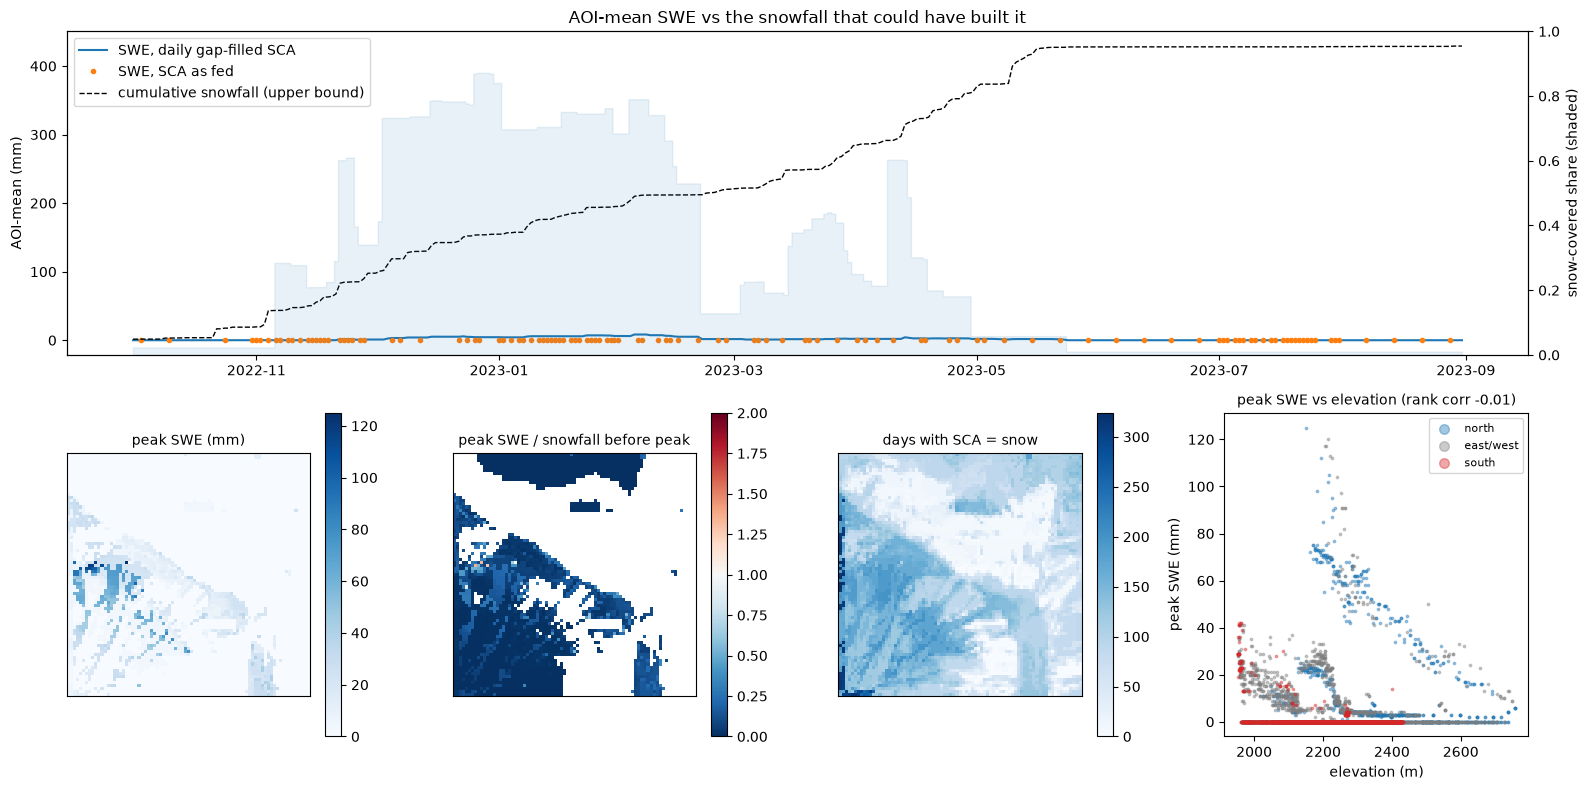

In [8]:
steps = np.diff(rec.t.values).astype('timedelta64[D]').astype(int)
check('SWE input', 'SCA time step is daily', f'{(steps == 1).mean():.0%} of steps are 1 day', '100 %', bool((steps == 1).all()))
check('SWE input', 'SCA unknown (205) share', f'{(rec_v == 205).mean():.2f}', '0 (UDF needs gap-free SCA)', bool((rec_v == 205).mean() == 0))

# Daily, gap-filled SCA: nearest clear value in time per pixel (stand-in for a complete reconstruction)
sca_daily = (rec.where(rec != 205).reindex(t=met.t.values)
             .interpolate_na('t', method='nearest', fill_value='extrapolate').fillna(205))
swe_daily = run_swe(sca_daily, (ta_d, pr_d, sw_d)).transpose('t', 'y', 'x')
sca_v, swe_v = sca_daily.values, swe_daily.values

pos_where_snow = (swe_v[sca_v == 100] > 0).mean()
zero_where_free = (swe_v[sca_v == 0] == 0).mean()
peak = swe_daily.max('t')
peak_idx = swe_daily.fillna(-1).argmax('t')
sf_before_peak = snowfall.cumsum('t').isel(t=peak_idx)
ratio = (peak / sf_before_peak.where(sf_before_peak > 0)).values
loss = -np.diff(swe_v, axis=0)
loss = loss[np.isfinite(loss) & (loss > 0)]
rho_peak = spearman(elev.values.ravel(), peak.values.ravel())
swe_mean_d = swe_daily.mean(['x', 'y'])
aoi_peak = float(swe_mean_d.max())

print(f'SCA time steps (days): {pd.Series(steps).value_counts().sort_index().to_dict()}')
print(f'as fed:           AOI-mean peak {float(swe_local.mean(["x", "y"]).max()):.0f} mm, NaN share {float(swe_local.isnull().mean()):.2f}')
print(f'daily gap-filled: AOI-mean peak {aoi_peak:.0f} mm on {str(swe_mean_d.idxmax().values)[:10]}, '
      f'pixel peak p50 {np.nanmedian(peak):.0f} / p95 {np.nanpercentile(peak, 95):.0f} / max {float(peak.max()):.0f} mm')
print(f'SWE > 0 where SCA = snow: {pos_where_snow:.2f} | SWE = 0 where SCA = no snow: {zero_where_free:.2f}')
print(f'peak SWE / snowfall before peak: median {np.nanmedian(ratio):.2f}, share > 1: {np.nanmean(ratio > 1):.2f}')
print(f'daily melt (SWE loss > 0): p50 {np.median(loss):.1f}, p99 {np.percentile(loss, 99):.1f}, max {loss.max():.1f} mm/day'
      if loss.size else 'no SWE loss days')

fig = plt.figure(figsize=(16, 8))
ax = fig.add_subplot(2, 1, 1)
ax.plot(swe_mean_d.t, swe_mean_d, label='SWE, daily gap-filled SCA')
ax.plot(swe_local.t, swe_local.mean(['x', 'y']), 'o', ms=3, label='SWE, SCA as fed')
ax.plot(snowfall.t, snowfall.mean(['x', 'y']).cumsum('t'), 'k--', lw=1, label='cumulative snowfall (upper bound)')
ax.set_ylabel('AOI-mean (mm)'); ax.legend(loc='upper left')
ax2 = ax.twinx(); ax2.fill_between(sca_daily.t, (sca_daily == 100).mean(['x', 'y']), color='tab:blue', alpha=0.1, step='mid')
ax2.set_ylabel('snow-covered share (shaded)'); ax2.set_ylim(0, 1)
ax.set_title('AOI-mean SWE vs the snowfall that could have built it')
panels = [('peak SWE (mm)', peak.values, 'Blues', None), ('peak SWE / snowfall before peak', ratio, 'RdBu_r', (0, 2)),
          ('days with SCA = snow', (sca_v == 100).sum(0), 'Blues', None)]
for i, (title, a, cm, lim) in enumerate(panels):
    axi = fig.add_subplot(2, 4, 5 + i)
    im = axi.imshow(a, cmap=cm, **(dict(vmin=lim[0], vmax=lim[1]) if lim else {})); axi.set_title(title, fontsize=10)
    axi.set_xticks([]); axi.set_yticks([]); plt.colorbar(im, ax=axi)
axi = fig.add_subplot(2, 4, 8)
for face, c in [('north', 'tab:blue'), ('east/west', 'tab:grey'), ('south', 'tab:red')]:
    s = facing.values == face
    axi.scatter(elev.values[s], peak.values[s], s=3, c=c, alpha=0.4, label=face)
axi.set_xlabel('elevation (m)'); axi.set_ylabel('peak SWE (mm)'); axi.legend(markerscale=4, fontsize=8)
axi.set_title(f'peak SWE vs elevation (rank corr {rho_peak:.2f})', fontsize=10)
plt.tight_layout()

check('SWE (daily)', 'SWE > 0 where SCA = snow', f'{pos_where_snow:.2f}', '> 0.9', pos_where_snow > 0.9)
check('SWE (daily)', 'SWE = 0 where SCA = no snow', f'{zero_where_free:.2f}', '1.0', zero_where_free > 0.999)
check('SWE (daily)', 'mass: peak SWE <= snowfall before peak', f'median ratio {np.nanmedian(ratio):.2f}, >1 in {np.nanmean(ratio > 1):.0%}',
      'median <= 1, >1 in < 10 %', np.nanmedian(ratio) <= 1 and np.nanmean(ratio > 1) < 0.1)
check('SWE (daily)', 'peak SWE increases with elevation', f'rank corr {rho_peak:.2f}', '> 0', rho_peak > 0)
check('SWE (daily)', 'daily melt rate', f'p99 {np.percentile(loss, 99):.0f} mm/day' if loss.size else 'no melt',
      'p99 <= 50 mm/day', bool(loss.size) and np.percentile(loss, 99) <= 50)
check('SWE (daily)', 'AOI-mean peak SWE', f'{aoi_peak:.0f} mm', '~100-400 mm (low-snow year, rough)', None)

**Interpretation**

- **As fed, the SWE UDF produces nothing useful.** The AOI-mean peak is 0 mm and 73 % of the values are NaN. The input SCA has 188 irregular dates: only 80 of the 187 steps are 1 day, the rest are 2-4 days, and 62 % of it is still 205. The UDF needs daily, gap-free SCA, so in the current pipeline SWE is not usable until the SCA gaps are closed.
- **Even with a daily, gap-filled SCA, SWE is ~50x too small.** The AOI-mean peak is 8 mm, with median pixel peak 0 mm and p95 28 mm, against ~430 mm of snowfall and an expected 100-400 mm. Where the SCA says snow, SWE is > 0 only 36 % of the time. "Mass conserved" passes (median ratio 0.02), but only because almost no mass is reconstructed.
- **Peak SWE does not increase with elevation (rank correlation −0.01).** It even *decreases* on the north-facing slope (blue points: ~120 mm at 2250 m to ~0 at 2700 m). This is the signature of a melt-limited reconstruction. The model can only "see" snow it has melted, and higher means colder means less modelled melt.
- **Melt rate p99 = 58 mm/day (max 125).** These are not physical melt days. They are the jumps where a period ends and SWE is set to 0 at melt-out.
- **Map artefact:** a strip at the left edge has snow on ~300 days (bottom middle). This probably comes from the stand-in gap filling: edge pixels with no later clear value keep "snow" into summer. It drives the outliers in section 6.1 and is not a UDF result.

### 6.1 Why is SWE so small? Melt budget

Reconstructed SWE can never exceed the melt the model produces while the pixel is snow-covered. The UDF's own `get_melt_pomeroy` is run on the daily inputs and its melt summed over each pixel's snow-covered days, then compared with the snowfall:
- **Melt ≪ snowfall:** the melt model is too weak for this climate → SWE underestimated (melt only above 2 °C, low `TF`, high albedo).
- **Melt ≈ snowfall:** the melt model is fine; the loss is in period detection (missing 100 → 0 transitions).

**How to read:** points on the 1:1 line = budget closes; below = too little melt; above = too much.

UDF parameters: {'temperature_threshold': 2.0, 'precipitation_threshold': 5.0, 'sca_increase_threshold': 10.0, 'TF': 0.24, 'SRF': 0.15, 'no_melt_days': 0}
on snow-covered days, T > 2.0 °C (the only days with melt) in 3% of cases
melt on snow-covered days: AOI mean 20 mm vs snowfall 429 mm -> median ratio 0.00
pixels with melt/snowfall > 1.5: 1%, < 0.5: 99%


,snow-covered pixel-days,warm (T > 2 °C) share of them,melt per snow pixel-day (mm)
month,,,
Oct,4495,0.74,2.62
Nov,52001,0.03,0.06
Dec,145856,0.00,0.00
Jan,140183,0.00,0.00
Feb,89878,0.00,0.00
Mar,57803,0.02,0.09
Apr,53943,0.08,0.37
May,8900,0.54,3.72
Jun,1980,0.97,11.70


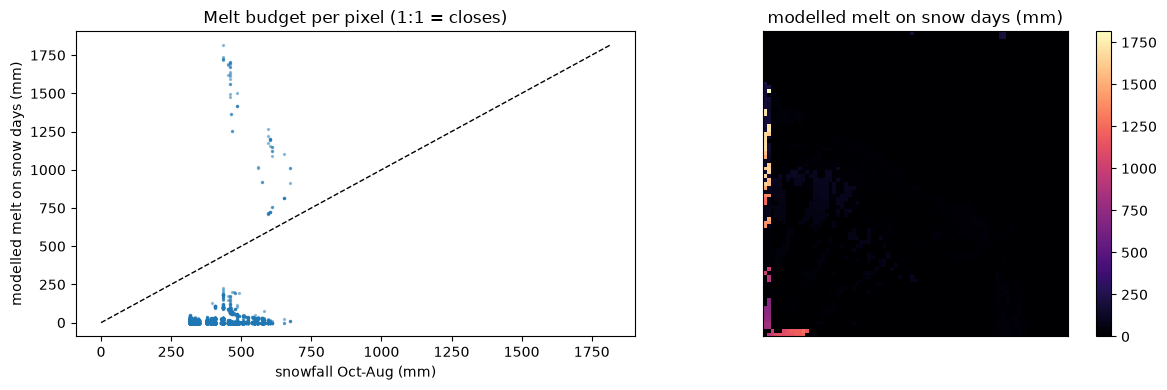

In [9]:
swe_udf = {}
exec(SWE_UDF.read_text(), swe_udf)  # reuse the UDF's own melt model
p = swe_udf['DEFAULTS']
sca_n = sca_v.astype(np.float32)
ta_n, pr_n, sw_n = (v.transpose('t', 'y', 'x').values.astype(np.float32) for v in (ta_d, pr_d, sw_d))
status, _ = swe_udf['get_status_and_delta'](sca_n, ta_n, pr_n, p)
melt = swe_udf['get_melt_pomeroy'](sca_n, ta_n, pr_n, sw_n, status, p)
on_snow = sca_n == 100
melt_on_snow = np.where(on_snow, melt, 0).sum(0)
warm_share = (ta_n > p['temperature_threshold'])[on_snow].mean()
sf_tot = snowfall.sum('t').values
melt_ratio = np.nanmedian(melt_on_snow / np.where(sf_tot > 0, sf_tot, np.nan))
mon = pd.DataFrame({'snow-covered pixel-days': on_snow.sum((1, 2)),
                    'warm (T > 2 °C) share of them': [(ta_n[i] > T_THR)[on_snow[i]].mean() if on_snow[i].any() else np.nan for i in range(len(ta_n))],
                    'melt per snow pixel-day (mm)': [melt[i][on_snow[i]].mean() if on_snow[i].any() else np.nan for i in range(len(ta_n))],
                    'month': sca_daily.t.dt.month.values}).groupby('month').agg(
    {'snow-covered pixel-days': 'sum', 'warm (T > 2 °C) share of them': 'mean', 'melt per snow pixel-day (mm)': 'mean'}).reindex(MONTHS).rename(index=MONTH_NAMES)
print(f'UDF parameters: {p}')
print(f'on snow-covered days, T > {p["temperature_threshold"]} °C (the only days with melt) in {warm_share:.0%} of cases')
print(f'melt on snow-covered days: AOI mean {melt_on_snow.mean():.0f} mm vs snowfall {sf_tot.mean():.0f} mm -> median ratio {melt_ratio:.2f}')
print(f'pixels with melt/snowfall > 1.5: {np.nanmean(melt_on_snow / np.where(sf_tot > 0, sf_tot, np.nan) > 1.5):.0%}, < 0.5: '
      f'{np.nanmean(melt_on_snow / np.where(sf_tot > 0, sf_tot, np.nan) < 0.5):.0%}')
display(mon.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sf_tot.ravel(), melt_on_snow.ravel(), s=2, alpha=0.4)
lim = max(sf_tot.max(), melt_on_snow.max()); axes[0].plot([0, lim], [0, lim], 'k--', lw=1)
axes[0].set_xlabel('snowfall Oct-Aug (mm)'); axes[0].set_ylabel('modelled melt on snow days (mm)'); axes[0].set_title('Melt budget per pixel (1:1 = closes)')
im = axes[1].imshow(melt_on_snow, cmap='magma'); axes[1].set_title('modelled melt on snow days (mm)'); plt.colorbar(im, ax=axes[1])
axes[1].set_xticks([]); axes[1].set_yticks([])
plt.tight_layout()

check('SWE (daily)', 'melt budget closes (melt on snow days / snowfall)', f'median {melt_ratio:.2f}', '~0.5-1.5', 0.5 <= melt_ratio <= 1.5)

**Interpretation:** the melt model is the bottleneck.

- In `get_melt_pomeroy` melt only happens on days with daily-mean T > 2 °C (`temperature_threshold`). On this AOI that is **3 % of snow-covered pixel-days**.
- Summed over each pixel's snow days, modelled melt is 20 mm on the AOI mean against 429 mm of snowfall (median ratio 0.00). 99 % of the pixels melt less than half their snowfall.
- The bulk of the points lie flat along the bottom of the scatter plot. The few points far above the 1:1 line are the left-edge strip from section 6 (snow kept all summer by the stand-in gap filling), not a model result.
- Yet sections 3-4 show the snow *does* disappear: south faces are bare by March, north faces by late April, while the monthly mean temperature is still below 0 °C (Mar −3.3, Apr −1.9 °C). At 2000-2750 m spring snow is removed by radiation-driven melt on days with a sub-zero daily mean (and by sublimation), which a daily-mean T > 2 °C gate cannot represent.

So the SWE underestimate is **not** a units or data problem. It comes from the melt parameterisation (`temperature_threshold` = 2 °C on daily-mean T, `TF` = 0.24, `SRF` = 0.15) applied at high elevation.

### 6.2 Melt-model sensitivity

The UDF is a faithful port of `get_melt_pomeroy` in the original SWE_reconstruction (`TF` = 0.24, `SRF` = 0.15, melt and the "melting" status only when daily-mean T > `temperature_threshold` = 2 °C). The original function's own defaults are `TF` = 1.2, `SRF` = 0.2256 (Pellicciotti ETI factors, ×24 to daily); its `main.py` overrides them with 0.24 / 0.15.

The UDF chain (status → melt → accumulation → SWE) is re-run on the same daily gap-filled inputs with the threshold at 2 / 0 / −2 °C and both factor sets. The threshold gates both the melt and the "melting" status, so it is the main knob. No code is changed; this only shows which parameter limits SWE.

**How to read:** a variant is plausible if the melt budget gets near 1, the AOI-mean peak SWE gets near 100-400 mm, SWE > 0 where SCA = snow gets near 1, and peak SWE rises with elevation (rank corr > 0).


,warm share of snow days,melt/snowfall (median),AOI-mean peak SWE (mm),pixel peak p50 / p95 (mm),SWE>0 where snow,rank corr peak vs elev
variant,,,,,,
"T>+2 °C, UDF 0.24/0.15",0.03,0.00,8.350000,0 / 28,0.37,-0.01
"T>+2 °C, ETI 1.2/0.2256",0.03,0.00,17.260000,0 / 55,0.37,-0.00
"T>+0 °C, UDF 0.24/0.15",0.07,0.00,16.930000,0 / 57,0.60,-0.13
"T>+0 °C, ETI 1.2/0.2256",0.07,0.00,28.940001,0 / 100,0.60,-0.12
"T>-2 °C, UDF 0.24/0.15",0.18,0.06,23.080000,11 / 140,0.67,-0.09
"T>-2 °C, ETI 1.2/0.2256",0.18,0.08,35.779999,15 / 215,0.63,-0.08


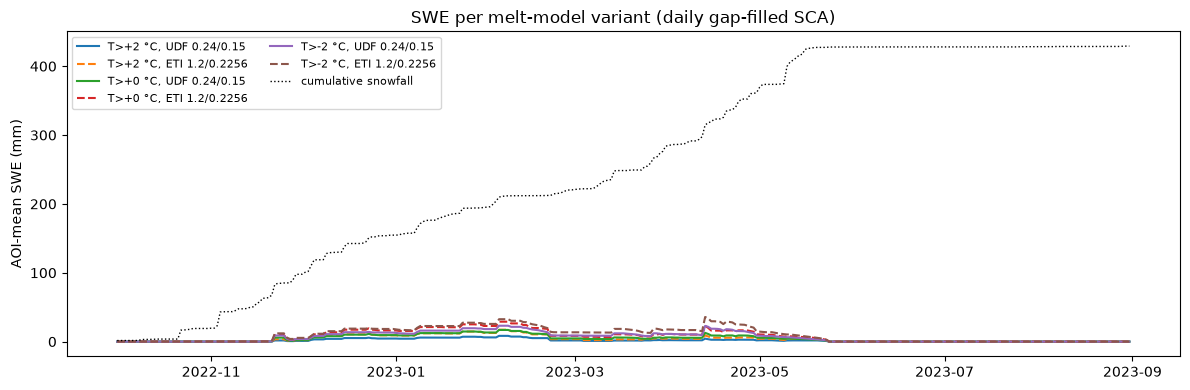

In [11]:
u = swe_udf
rows, swe_runs = [], {}
for thr in (2.0, 0.0, -2.0):
    for fname, tf, srf in (('UDF 0.24/0.15', 0.24, 0.15), ('ETI 1.2/0.2256', 1.2, 0.2256)):
        pv = {**p, 'temperature_threshold': thr, 'TF': tf, 'SRF': srf}
        st, de = u['get_status_and_delta'](sca_n, ta_n, pr_n, pv)
        me = u['get_melt_pomeroy'](sca_n, ta_n, pr_n, sw_n, st, pv)
        ss, ta_acc = u['compute_state_and_accumulation'](sca_n, me, st, de)
        sw_ = u['get_swe'](sca_n, me, st, de, ss, ta_acc)
        pk = np.nanmax(sw_, 0)
        mos = np.where(on_snow, me, 0).sum(0)
        key = f'T>{thr:+.0f} °C, {fname}'
        swe_runs[key] = np.nanmean(sw_, axis=(1, 2))
        rows.append({'variant': key,
                     'warm share of snow days': (ta_n > thr)[on_snow].mean(),
                     'melt/snowfall (median)': np.nanmedian(mos / np.where(sf_tot > 0, sf_tot, np.nan)),
                     'AOI-mean peak SWE (mm)': np.nanmax(swe_runs[key]),
                     'pixel peak p50 / p95 (mm)': f'{np.nanmedian(pk):.0f} / {np.nanpercentile(pk, 95):.0f}',
                     'SWE>0 where snow': (sw_[sca_n == 100] > 0).mean(),
                     'rank corr peak vs elev': spearman(elev.values.ravel(), pk.ravel())})
sens = pd.DataFrame(rows).set_index('variant')
display(sens.round(2))

fig, ax = plt.subplots(figsize=(12, 4))
for k, v in swe_runs.items():
    ax.plot(sca_daily.t, v, ls='-' if 'UDF' in k else '--', label=k)
ax.plot(snowfall.t, snowfall.mean(['x', 'y']).cumsum('t'), 'k:', lw=1, label='cumulative snowfall')
ax.set_ylabel('AOI-mean SWE (mm)'); ax.legend(fontsize=8, ncol=2); ax.set_title('SWE per melt-model variant (daily gap-filled SCA)')
plt.tight_layout()

best = sens['melt/snowfall (median)'].sub(1).abs().idxmin()
check('SWE (daily)', 'melt-model sensitivity: variant closest to budget closure', best,
      'informative only', None)


**Interpretation:** the parameters matter, but they are not the main cause.

- **The port is faithful.** The UDF reproduces the original `get_melt_pomeroy` + `main.py` settings exactly. The small SWE is not a porting bug.
- **Raising melt helps only a little.** With the ETI factors (5x the temperature factor) and a threshold of −2 °C, the AOI-mean peak goes from 8 to 36 mm and the melt budget from 0.00 to 0.08. That is still ~10x short of snowfall, and peak SWE still does not rise with elevation (rank corr −0.08).
- **Even at −2 °C only 18 % of snow-covered days are "warm".** The SCA shows snow disappearing in March-April while daily-mean T is mostly below −2 °C. A temperature-gated melt model cannot produce that ablation at any reasonable threshold. Two explanations remain: thin low-snow-year snow removed by sublimation/radiation, and false melt-outs in the SCA (median 6 snow ↔ no-snow flips per pixel, section 4). These split the season into many short periods, and each one collects almost no melt.
- **Conclusion:** the degree-day/ETI parameterisation is a limitation of the original method at 2000-2750 m in a cold, low-snow year. On this AOI, the larger lever is SCA quality: fewer flips, and recovering the clear days lost in the SCF step. Retuning `TF`/`SRF`/threshold alone will not close the budget. It should also be agreed with the method authors before changing defaults.
- Side note: `downscale_variables.py` uses `lapse_rate_sohem[1]` (8.1 K/km, southern-hemisphere February) for every date. For a northern site the monthly values are 4.4-8.2 K/km. This makes high pixels slightly colder in winter/spring, but it is small next to the effects above.


## 7. Scorecard

In [12]:
score = pd.DataFrame(checks.values())
print(score['result'].value_counts().to_dict())
with pd.option_context('display.max_colwidth', None):
    display(score)

{'FAIL': 11, 'PASS': 10, 'CHECK': 3}


,area,check,value,expected,result
0,S2 snow map,snow fraction bias vs MODIS,-0.07 (n=6),|bias| < 0.15,PASS
1,S2 snow map,snow fraction correlation vs MODIS,r = 0.95,r > 0.7,PASS
2,S2 snow map,pixel agreement vs MODIS SCF >= 50 %,0.71,> 0.8,FAIL
3,S2 snow map,S2 all cloud while MODIS clear,11 / 17 days,< 20 % of days,FAIL
4,S2 snow map,spring snow increases with elevation,rank corr 0.95,> 0,PASS
5,S2 snow map,spring snow north > south,N 0.56 / S 0.04,N > S,PASS
6,S2 snow map,Jul-Aug clear obs available,"0 pixel obs, snow nan","many obs, snow ~0",FAIL
7,SCA reconstruction,keeps clear S2 observations,1.0000,1.0,PASS
8,SCA reconstruction,unknown (205) left,0.62 (input 0.87),< 0.10,FAIL
9,SCA reconstruction,snow/no-snow flips per pixel,"median 6, p90 8",median <= 6,PASS


## 8. Conclusion

Run of 2026-11-18: **10 PASS, 11 FAIL, 3 CHECK.**

**What is scientifically sound**
- The S2 snow maps, *when produced*, agree with MODIS (r = 0.95, bias −0.07), and they show the right physics: more snow higher up, much more on north than on south faces.
- The SCA reconstruction never changes clear observations. Its melt-out follows terrain and aspect: south faces in late March, north faces in late April, +4.4 days per 100 m.
- The meteo forcing (≈ 430 mm of snowfall, increasing with elevation) is plausible.

**What is not, ranked by impact**
1. **SWE is ~50x too small** (AOI peak 8 mm vs 100-400 mm expected). The UDF is a faithful port of the original `get_melt_pomeroy` (melt only on daily-mean T > 2 °C, which is 3 % of snow days here). Section 6.2 shows that retuning alone does not fix it: even at −2 °C with ETI factors the budget only reaches 0.08. The snow disappears at sub-zero temperatures (thin low-snow-year snow and/or SCA flips), which a temperature-gated melt model cannot reconstruct. This is a method limitation to discuss with the authors.
2. **Clear scenes without both training classes are lost.** `representative_pixels.py` returns 255 when the SVM lacks a class, and `snow_map` turns it into 205. The SCA UDF then treats that day like "no image", so the clear observation is gone. As a result, 11 of 17 MODIS-clear days are lost and there are no S2 observations from June to October. SnowFLAKES itself never writes 205/255 here: with `find_closest_model` (on for Senales) it reuses the SVM of the nearest date that had both classes, and otherwise it skips the scene. Planned fix: the same closest-date fallback, else NaN (no image). It should not be 255, because the SCA UDF never fills 255.
3. **SCA is not gap-free or daily** (62 % unknown, 2-4 day steps), partly because of point 2 and partly because CDSE MODIS is sparse (99/335 days). The SWE UDF fed with it returns 0 mm / 73 % NaN.
4. **The 5 mm/day accumulation threshold** ignores 37 % of the snowfall. Totals are kept, but the timing is distorted.
5. **Borderline temporal noise** in SCA (median 6 flips per pixel), on the north-facing slope. It also cuts the season into short periods for the SWE reconstruction.

**Limits of this test:** a 1.5 x 1.5 km AOI, one low-snow year, no in-situ SWE, and 6 days of good S2/MODIS overlap. The PASS results are therefore indicative, but the FAILs above are large and point to clear mechanisms.
